# Flood Response & Evacuation Planner — Final Integrated Notebook

**Execution order:** Run the notebook from top to bottom in Google Colab. When prompted in the data-upload cell, upload the project's historical flood `.kml` file. The road-network download and dashboard tunnel require an active internet connection.

The Member 3 evaluation, route-coordinate export, and Member 4 dashboard have been integrated. The dashboard map uses embedded Folium HTML rather than the separate `streamlit-folium` component, and route IDs and node coordinates are exported from the same routing graph.

**Dashboard:** Run the final launch cell last. Keep it running while using the temporary Cloudflare URL printed in its output. A new URL is generated whenever the tunnel restarts.

This is a simulation prototype; it is not a real-world emergency dispatch system.

The libraries will help us download roads, process geographical information and create our interactive map.

In [ ]:

!pip install osmnx folium geopandas networkx pandas numpy


In [ ]:
# MEMBER 1: DOWNLOAD / LOAD VELACHERY ROAD NETWORK
# Uses a cached GraphML file when available. The first download depends on Overpass availability.

import os
import time
import osmnx as ox
import pandas as pd
import geopandas as gpd
import networkx as nx
import folium

ox.settings.use_cache = True
ox.settings.log_console = True
ox.settings.timeout = 300

graph_path = "/content/velachery_road_network.graphml"

if os.path.exists(graph_path):
    print("Loading saved Velachery road network...")
    G = ox.load_graphml(graph_path)
else:
    G = None
    last_error = None
    # Keep the first request reasonably small; retry transient Overpass 502/504 errors.
    for radius in (1000, 750):
        for attempt in range(1, 4):
            try:
                print(f"Requesting Velachery drive network: radius={radius}m, attempt={attempt}/3")
                G = ox.graph_from_address(
                    "Velachery, Chennai, Tamil Nadu, India",
                    dist=radius,
                    network_type="drive",
                    simplify=True
                )
                if G.number_of_nodes() == 0:
                    raise RuntimeError("OpenStreetMap returned an empty road graph.")
                ox.save_graphml(G, filepath=graph_path)
                print("Road network downloaded and cached for this Colab runtime.")
                break
            except Exception as exc:
                last_error = exc
                wait = 15 * (2 ** (attempt - 1))
                print(f"Download failed ({type(exc).__name__}): {exc}")
                if attempt < 3:
                    print(f"Retrying in {wait} seconds...")
                    time.sleep(wait)
        if G is not None:
            break
    if G is None:
        raise RuntimeError(
            "Overpass is currently overloaded. Wait and rerun this cell only. "
            "Do not rerun the full notebook."
        ) from last_error

nodes, edges = ox.graph_to_gdfs(G)
print("Road network ready!")
print("Nodes:", len(nodes))
print("Edges:", len(edges))


Puprose:

Downloads actual road data from OpenStreetMap.


Identifies road intersections (nodes).


Identifies roads connecting intersections (edges).


Converts everything into tables for further processing.

**Road network map of Velachery, Chennai:**

It shows:
- Streets and roads.
- Buildings and surrounding areas.
- Localities and geographical features.
- The general layout of the city.

In [ ]:

import folium

center_lat = nodes.geometry.y.mean()
center_lon = nodes.geometry.x.mean()

# Create map using Esri tiles
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=14,
    tiles=None
)

# Add Esri background map
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, © OpenStreetMap contributors",
    name="Esri Street Map"
).add_to(m)

# Add road network
folium.GeoJson(
    edges.to_json(),
    name="Road Network",
    style_function=lambda feature: {
        "color": "orange",
        "weight": 1.5
    }
).add_to(m)

folium.LayerControl().add_to(m)

display(m)

m.save("velachery_roads_map.html")

print("Map created successfully!")



These orange lines represent the roads downloaded from OpenStreetMap.

The roads are represented using two concepts:
- Nodes: Points representing road intersections or endpoints.
- Edges: Connections between those points, representing roads.

In [ ]:
from google.colab import files
import os

print("Upload the historical flood KML file.")
uploaded = files.upload()

kml_files = [name for name in uploaded if name.lower().endswith(".kml")]
if not kml_files:
    raise FileNotFoundError("No .kml file was uploaded. Please upload the flood dataset.")

kml_file = kml_files[0]
flood_file = os.path.join("/content", kml_file)
print("KML dataset:", flood_file)
print("File exists:", os.path.exists(flood_file))


In [ ]:
# Google Drive mounting is intentionally skipped.
# The KML file and all project outputs are stored in /content for this Colab session.
print("Using local Colab storage. Google Drive is not required.")


In [ ]:
import geopandas as gpd

flood_data = gpd.read_file(
    flood_file,
    driver="KML"
)

print("Flood dataset loaded:", len(flood_data))
display(flood_data.head())

In [ ]:

# import geopandas as gpd

# flood_file = "/content/drive/MyDrive/814ca028-4c84-4bd0-aa67-6dbaeb9b6ba5.kml"
# # Load KML data
# flood_data = gpd.read_file(
#     flood_file,
#     driver="KML"
# )
# print("Flood dataset loaded successfully!")
# print("Total flood records:", len(flood_data))

# display(flood_data.head())


UNDERSTANDING DATASET

In [ ]:

print("Dataset information:")
print(flood_data.info())

print("\nAvailable columns:")
print(flood_data.columns.tolist())

print("\nCoordinate system:")
print(flood_data.crs)

print("\nSample records:")
display(flood_data.head(10))


In [ ]:

# Select important columns
flood_clean = flood_data[
    [
        "F_ID",
        "F_LATITUDE",
        "F_LONGITUDE",
        "DEPTH",
        "ZONE",
        "WARD",
        "F_REMARKS",
        "geometry"
    ]
].copy()

# Check missing values
print("Missing values:")
print(flood_clean.isnull().sum())

# Display useful records
print("\nFlood data:")
display(flood_clean.head(10))


Understanding the water-depth values
as the RL agent will eventually use flood severity to decide whether a road is safe.

In [ ]:

print("Water depth statistics:")
print(flood_clean["DEPTH"].describe())

print("\nMinimum depth:",
      flood_clean["DEPTH"].min())

print("Maximum depth:",
      flood_clean["DEPTH"].max())

print("Average depth:",
      flood_clean["DEPTH"].mean())


Checking the geographical coordinates

In [ ]:

print("Latitude range:")
print(flood_clean["F_LATITUDE"].min(),
      flood_clean["F_LATITUDE"].max())

print("\nLongitude range:")
print(flood_clean["F_LONGITUDE"].min(),
      flood_clean["F_LONGITUDE"].max())

# Check valid coordinates
valid_flood = flood_clean.dropna(
    subset=["F_LATITUDE", "F_LONGITUDE", "DEPTH"]
).copy()

print("\nValid flood records:", len(valid_flood))


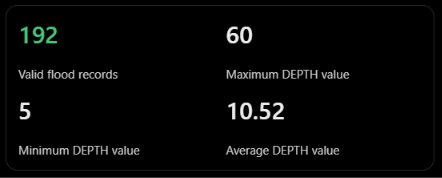

In [ ]:
# Convert both datasets to projected coordinates
roads_projected = edges.to_crs(epsg=32644)

flood_projected = flood_clean.to_crs(epsg=32644)

# Remove records without valid geometry
flood_projected = flood_projected[
    flood_projected.geometry.notna()
].copy()

# Find flood locations within 500 metres of roads
velachery_flood = gpd.sjoin_nearest(
    flood_projected,
    roads_projected[["geometry"]],
    how="inner",
    max_distance=500,
    distance_col="nearest_road_m"
)

# Remove duplicate flood records if nearest roads are tied
velachery_flood = velachery_flood[
    ~velachery_flood.index.duplicated(keep="first")
].copy()

# Remove unnecessary join column
if "index_right" in velachery_flood.columns:
    velachery_flood.drop(
        columns=["index_right"],
        inplace=True
    )

print("Flood processing completed!")

print("Total Chennai flood records:", len(flood_clean))

print("Flood records near Velachery roads:",
      len(velachery_flood))

display(velachery_flood.head(10))

In [ ]:

# Create a copy of your existing map
flood_map = m

# Convert selected flood points back to latitude/longitude
velachery_flood_map = velachery_flood.to_crs(epsg=4326)

# Add historical flood locations
for _, row in velachery_flood_map.iterrows():

    lat = row.geometry.y
    lon = row.geometry.x

    folium.CircleMarker(
        location=[lat, lon],
        radius=5,
        color="red",
        fill=True,
        fill_color="red",
        fill_opacity=0.7,
        popup=f"Flood ID: {row['F_ID']} | Depth: {row['DEPTH']}"
    ).add_to(flood_map)

display(flood_map)

flood_map.save("velachery_flood_map.html")


In [ ]:
print(velachery_flood["F_REMARKS"].value_counts())
print(velachery_flood["DEPTH"].unique()[:20])

In [ ]:
# Member 2 work....

In [ ]:
# INSPECT RL INPUT DATA

print("ROAD NETWORK")
print("-------------")

print("Total nodes:", len(nodes))
print("Total edges:", len(edges))

print("\nRoad columns:")
print(edges.columns.tolist())

print("\nSample road data:")
display(edges.head(3))


print("\nFLOOD DATA")
print("----------")

print("Total flood records:", len(velachery_flood))

print("\nFlood columns:")
print(velachery_flood.columns.tolist())

print("\nSample flood data:")
display(velachery_flood.head(3))


print("\nGRAPH INFORMATION")
print("-----------------")

print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())

print("\nSample node:")
print(next(iter(G.nodes(data=True))))

print("\nSample edge:")
print(next(iter(G.edges(data=True))))

In [ ]:
# REWARD FUNCTION

def calculate_reward(
    old_distance,
    new_distance,
    reached_destination,
    flood_risk,
    invalid_action=False
):

    reward = 0

    # Destination reached
    if reached_destination:
        reward += 100

    # Invalid movement
    elif invalid_action:
        reward -= 20

    else:

        # Encourage progress
        if new_distance < old_distance:
            reward += 10

        # Penalize moving away
        elif new_distance > old_distance:
            reward -= 10

        # Penalize historical flood risk
        if flood_risk:
            reward -= 30

        # Small movement cost
        reward -= 1

    return reward

In [ ]:
print("Successful evacuation:",
      calculate_reward(1000, 0, True, False))

print("Safe movement:",
      calculate_reward(1000, 800, False, False))

print("Flood-risk road:",
      calculate_reward(1000, 800, False, True))

print("Moving away:",
      calculate_reward(800, 1000, False, False))

print("Invalid action:",
      calculate_reward(1000, 1000, False, False, True))

In [ ]:
!pip install gymnasium

In [ ]:
# PREPARE ROAD-LEVEL FLOOD RISK

import geopandas as gpd

# Preserve all required road attributes
roads_projected = edges.reset_index()[
    ["u", "v", "key", "length", "geometry"]
].copy()

# Convert to metre-based coordinate system
roads_projected = gpd.GeoDataFrame(
    roads_projected,
    geometry="geometry",
    crs=edges.crs
).to_crs(epsg=32644)

# Prepare flood data
flood_projected = flood_clean.to_crs(epsg=32644)

# Remove invalid geometries
roads_projected = roads_projected[
    roads_projected.geometry.notna()
].copy()

flood_projected = flood_projected[
    flood_projected.geometry.notna()
].copy()

# Create unique road IDs
roads_projected = roads_projected.reset_index(drop=True)
roads_projected["road_id"] = range(len(roads_projected))

# Match historical flood locations with nearby roads
flood_road_matches = gpd.sjoin_nearest(
    flood_projected,
    roads_projected[["road_id", "geometry"]],
    how="inner",
    max_distance=500,
    distance_col="flood_distance"
)

# Identify historically flood-associated roads
flood_risk_edges = set(
    flood_road_matches["road_id"].unique()
)

# Assign flood risk
roads_projected["flood_risk"] = (
    roads_projected["road_id"].isin(flood_risk_edges)
).astype(int)

print("Road-level flood risk prepared!")

print("Total road segments:", len(roads_projected))

print("Historically flood-associated roads:",
      roads_projected["flood_risk"].sum())

display(
    roads_projected[
        ["road_id", "u", "v", "length", "flood_risk"]
    ].head(10)
)

In [ ]:
# PREPARE RL ROAD NETWORK

import networkx as nx
import numpy as np
import random
import gymnasium as gym
from gymnasium import spaces

# Create an undirected routing graph for our initial prototype
RL_graph = G.to_undirected()

# Create road flood-risk dictionary
road_risk = {}

for _, row in roads_projected.iterrows():

    edge = (row["u"], row["v"])

    risk_value = int(row["flood_risk"])
    road_risk[edge] = max(road_risk.get(edge, 0), risk_value)
    road_risk[(row["v"], row["u"])] = max(
        road_risk.get((row["v"], row["u"]), 0), risk_value
    )

# Find connected components
largest_component = max(
    nx.connected_components(RL_graph),
    key=len
)

# Keep the largest connected component
RL_graph = RL_graph.subgraph(
    largest_component
).copy()

# Find maximum number of connected neighbours
MAX_ACTIONS = max(
    dict(RL_graph.degree()).values()
)

print("RL road network prepared!")

print("RL nodes:", RL_graph.number_of_nodes())
print("RL edges:", RL_graph.number_of_edges())
print("Maximum actions:", MAX_ACTIONS)
print("Flood-risk records:", len(road_risk))

In [ ]:
# CUSTOM GYMNASIUM ENVIRONMENT

class FloodEvacuationEnv(gym.Env):

    def __init__(self, graph, road_risk):

        super().__init__()

        self.graph = graph
        self.road_risk = road_risk

        self.nodes = list(graph.nodes())

        self.max_steps = 100

        # Fixed action space
        self.action_space = spaces.Discrete(MAX_ACTIONS)

        # State: current coordinates, destination coordinates,
        # and remaining distance
        self.observation_space = spaces.Box(
            low=0,
            high=1,
            shape=(5,),
            dtype=np.float32
        )

        self.reset()

    def get_observation(self):

        current = self.graph.nodes[self.current_node]
        destination = self.graph.nodes[self.destination]

        return np.array([
            current["y"] / 90,
            (current["x"] + 180) / 360,
            destination["y"] / 90,
            (destination["x"] + 180) / 360,
            min(self.remaining_distance / 10000, 1)
        ], dtype=np.float32)

    def reset(self, seed=None, options=None):

        super().reset(seed=seed)

        self.current_node = random.choice(self.nodes)

        reachable = list(
            nx.node_connected_component(
                self.graph,
                self.current_node
            )
        )

        self.destination = random.choice(reachable)

        while self.destination == self.current_node:

            self.destination = random.choice(reachable)

        self.steps = 0

        self.remaining_distance = nx.shortest_path_length(
            self.graph,
            self.current_node,
            self.destination,
            weight="length"
        )

        return self.get_observation(), {}

    def step(self, action):

        self.steps += 1

        neighbours = sorted(
            self.graph.neighbors(self.current_node)
        )

        # Invalid action
        if action >= len(neighbours):

            reward = -20

            terminated = False
            truncated = self.steps >= self.max_steps

            return (
                self.get_observation(),
                reward,
                terminated,
                truncated,
                {}
            )

        next_node = neighbours[action]

        edge = (self.current_node, next_node)

        flood_risk = self.road_risk.get(edge, 0)

        old_distance = self.remaining_distance

        road_length = self.graph[
            self.current_node
        ][next_node][0].get("length", 1)

        self.current_node = next_node

        new_distance = nx.shortest_path_length(
            self.graph,
            self.current_node,
            self.destination,
            weight="length"
        )

        reached = (
            self.current_node == self.destination
        )

        reward = calculate_reward(
            old_distance,
            new_distance,
            reached,
            bool(flood_risk)
        )

        self.remaining_distance = new_distance

        terminated = reached

        truncated = self.steps >= self.max_steps

        return (
            self.get_observation(),
            reward,
            terminated,
            truncated,
            {"flood_risk": flood_risk}
        )


print("Flood Evacuation Environment Created!")

In [ ]:
# TEST RL ENVIRONMENT

env = FloodEvacuationEnv(
    RL_graph,
    road_risk
)

state, info = env.reset()

print("Environment test successful!")

print("Initial State:", state)

print("State Shape:", state.shape)

print("Action Space:", env.action_space)

print("Observation Space:", env.observation_space)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

In [ ]:
# DQN NEURAL NETWORK

class DQN(nn.Module):

    def __init__(self, state_size, action_size):

        super(DQN, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(state_size, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, action_size)
        )

    def forward(self, state):

        return self.network(state)


# Initialize DQN
state_size = 5
action_size = env.action_space.n

policy_network = DQN(state_size, action_size)

target_network = DQN(state_size, action_size)

target_network.load_state_dict(
    policy_network.state_dict()
)

target_network.eval()

print("DQN Neural Network Created!")

print(policy_network)

In [ ]:
# Test DQN prediction

sample_state, _ = env.reset()

state_tensor = torch.FloatTensor(
    sample_state
).unsqueeze(0)

with torch.no_grad():

    q_values = policy_network(state_tensor)

print("Input State:", sample_state)

print("Predicted Q-values:", q_values)

print("Best Action:", torch.argmax(q_values).item())

In [ ]:
# EXPERIENCE REPLAY MEMORY

from collections import deque
import random
import numpy as np

class ReplayMemory:

    def __init__(self, capacity=10000):

        self.memory = deque(maxlen=capacity)

    def push(self, state, action, reward,
             next_state, done):

        self.memory.append((
            state,
            action,
            reward,
            next_state,
            done
        ))

    def sample(self, batch_size):

        batch = random.sample(
            self.memory,
            batch_size
        )

        states, actions, rewards, next_states, dones = zip(*batch)

        return (
            np.array(states, dtype=np.float32),
            np.array(actions, dtype=np.int64),
            np.array(rewards, dtype=np.float32),
            np.array(next_states, dtype=np.float32),
            np.array(dones, dtype=np.float32)
        )

    def __len__(self):

        return len(self.memory)


# Initialize replay memory
replay_memory = ReplayMemory(capacity=10000)

print("Experience Replay Memory initialized!")
print("Memory capacity:", 10000)

In [ ]:
# TEST REPLAY MEMORY

state, _ = env.reset()

next_state, reward, terminated, truncated, info = env.step(0)

done = terminated or truncated

replay_memory.push(
    state,
    0,
    reward,
    next_state,
    done
)

print("Experience stored successfully!")

print("Memory size:", len(replay_memory))

print("Stored experience:")
print(replay_memory.memory[0])

In [ ]:
# DQN OPTIMIZER

LEARNING_RATE = 0.001
GAMMA = 0.99

optimizer = optim.Adam(
    policy_network.parameters(),
    lr=LEARNING_RATE
)

loss_function = nn.SmoothL1Loss()

print("DQN optimizer initialized!")
print("Learning rate:", LEARNING_RATE)
print("Discount factor:", GAMMA)
print("Loss function: Smooth L1 Loss")

In [ ]:
# DQN TRAINING CONFIGURATION

EPISODES = 100
BATCH_SIZE = 64

GAMMA = 0.99

EPSILON = 1.0
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.995

TARGET_UPDATE = 10

print("DQN Training Configuration Ready!")
print("Episodes:", EPISODES)
print("Batch Size:", BATCH_SIZE)
print("Discount Factor:", GAMMA)
print("Initial Epsilon:", EPSILON)

In [ ]:
# VALID ACTION MASKING

def get_valid_action_mask(env):

    mask = np.zeros(
        env.action_space.n,
        dtype=bool
    )

    neighbours = sorted(
        env.graph.neighbors(env.current_node)
    )

    mask[:len(neighbours)] = True

    return mask


print("Action masking implemented!")

print(
    "Valid actions:",
    np.where(get_valid_action_mask(env))[0]
)

In [ ]:
# MASKED REPLAY MEMORY

from collections import deque

class MaskedReplayMemory:

    def __init__(self, capacity=10000):

        self.memory = deque(maxlen=capacity)

    def push(self, state, action, reward,
             next_state, done, next_mask):

        self.memory.append((
            state,
            action,
            reward,
            next_state,
            done,
            next_mask
        ))

    def sample(self, batch_size):

        batch = random.sample(
            self.memory,
            batch_size
        )

        states, actions, rewards, next_states, dones, masks = zip(*batch)

        return (
            np.array(states, dtype=np.float32),
            np.array(actions, dtype=np.int64),
            np.array(rewards, dtype=np.float32),
            np.array(next_states, dtype=np.float32),
            np.array(dones, dtype=np.float32),
            np.array(masks, dtype=bool)
        )

    def __len__(self):

        return len(self.memory)


replay_memory = MaskedReplayMemory(10000)

print("Masked Replay Memory Ready!")

In [ ]:
# DQN TRAINING ALGORITHM

def train_dqn():

    global EPSILON

    episode_rewards = []
    successful_episodes = 0

    for episode in range(EPISODES):

        state, _ = env.reset()

        total_reward = 0

        done = False

        while not done:

            valid_mask = get_valid_action_mask(env)

            valid_actions = np.where(valid_mask)[0]

            # Epsilon-greedy action selection
            if random.random() < EPSILON:

                action = random.choice(
                    valid_actions.tolist()
                )

            else:

                state_tensor = torch.FloatTensor(
                    state
                ).unsqueeze(0)

                with torch.no_grad():

                    q_values = policy_network(state_tensor)

                    q_values[0, ~torch.tensor(valid_mask)] = -1e9

                    action = torch.argmax(
                        q_values
                    ).item()

            # Execute action
            next_state, reward, terminated, truncated, info = env.step(action)

            done = terminated or truncated

            # Get next valid actions
            if done:

                next_mask = np.zeros(
                    action_size,
                    dtype=bool
                )

            else:

                next_mask = get_valid_action_mask(env)

            # Store experience
            replay_memory.push(
                state,
                action,
                reward,
                next_state,
                done,
                next_mask
            )

            state = next_state

            total_reward += reward

            # Train using experience replay
            if len(replay_memory) >= BATCH_SIZE:

                states, actions, rewards, next_states, dones, masks = (
                    replay_memory.sample(BATCH_SIZE)
                )

                states = torch.FloatTensor(states)

                actions = torch.LongTensor(actions)

                rewards = torch.FloatTensor(rewards)

                next_states = torch.FloatTensor(next_states)

                dones = torch.FloatTensor(dones)

                masks = torch.BoolTensor(masks)

                # Current Q values
                current_q = policy_network(states).gather(
                    1,
                    actions.unsqueeze(1)
                ).squeeze(1)

                # Target Q values
                with torch.no_grad():

                    next_q = target_network(next_states)

                    next_q = next_q.masked_fill(
                        ~masks,
                        -1e9
                    )

                    max_next_q = next_q.max(dim=1)[0]

                    max_next_q[dones == 1] = 0

                    target_q = rewards + GAMMA * max_next_q * (1 - dones)

                # Calculate loss
                loss = loss_function(
                    current_q,
                    target_q
                )

                optimizer.zero_grad()

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    policy_network.parameters(),
                    1.0
                )

                optimizer.step()

        episode_rewards.append(total_reward)

        if terminated:
            successful_episodes += 1

        # Reduce exploration
        EPSILON = max(
            EPSILON_MIN,
            EPSILON * EPSILON_DECAY
        )

        # Update target network
        if (episode + 1) % TARGET_UPDATE == 0:

            target_network.load_state_dict(
                policy_network.state_dict()
            )

        print(
            f"Episode {episode + 1}/{EPISODES} | "
            f"Reward: {total_reward:.2f} | "
            f"Epsilon: {EPSILON:.3f} | "
            f"Successes: {successful_episodes}"
        )

    return episode_rewards, successful_episodes


print("DQN Training Function Created!")

In [ ]:
# START TRAINING

episode_rewards, successful_episodes = train_dqn()

print("\n========== TRAINING COMPLETED ==========")

print("Total Episodes:", EPISODES)

print("Successful Episodes:", successful_episodes)

print("Average Reward:", np.mean(episode_rewards))

In [ ]:
# DQN MODEL EVALUATION

def evaluate_dqn(episodes=20):

    evaluation_rewards = []
    successful = 0
    flood_roads_encountered = 0
    total_steps = 0

    for episode in range(episodes):

        state, _ = env.reset()

        total_reward = 0
        done = False

        while not done:

            valid_mask = get_valid_action_mask(env)

            state_tensor = torch.FloatTensor(
                state
            ).unsqueeze(0)

            with torch.no_grad():

                q_values = policy_network(state_tensor)

                mask_tensor = torch.as_tensor(
                    valid_mask,
                    dtype=torch.bool
                )

                q_values[0, ~mask_tensor] = -1e9

                action = torch.argmax(
                    q_values
                ).item()

            next_state, reward, terminated, truncated, info = env.step(action)

            total_reward += reward

            total_steps += 1

            if info.get("flood_risk", 0) == 1:
                flood_roads_encountered += 1

            state = next_state

            done = terminated or truncated

        if terminated:
            successful += 1

        evaluation_rewards.append(total_reward)

    print("========== MODEL EVALUATION ==========")

    print("Total Episodes:", episodes)

    print("Successful Episodes:", successful)

    print("Success Rate:", round(successful / episodes * 100, 2), "%")

    print("Average Reward:", round(np.mean(evaluation_rewards), 2))

    print("Flood-Risk Roads Encountered:", flood_roads_encountered)

    print("Average Steps:", round(total_steps / episodes, 2))

    return evaluation_rewards


evaluation_rewards = evaluate_dqn(episodes=20)

In [ ]:
# TRAINING REWARD GRAPH

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    episode_rewards,
    label="Episode Reward"
)

plt.xlabel("Episodes")

plt.ylabel("Total Reward")

plt.title("DQN Training Performance")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
# MOVING AVERAGE

window = 10

moving_average = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(12, 5))

plt.plot(
    moving_average,
    label="Moving Average Reward"
)

plt.xlabel("Episodes")

plt.ylabel("Average Reward")

plt.title("DQN Learning Progress")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
# SAVE TRAINED MODEL

torch.save(
    policy_network.state_dict(),
    "flood_evacuation_dqn.pth"
)

print("DQN Model Saved Successfully!")

In [ ]:
from google.colab import files

files.download("flood_evacuation_dqn.pth")

In [ ]:
# SAVE TRAINING RESULTS LOCALLY (no Google Drive mount required)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

output_folder = "/content/RL_Project_Outputs"
os.makedirs(output_folder, exist_ok=True)

training_results = pd.DataFrame({
    "Episode": range(1, len(episode_rewards) + 1),
    "Reward": episode_rewards
})
training_results.to_csv(
    os.path.join(output_folder, "training_results.csv"),
    index=False
)

plt.figure(figsize=(12, 6))
plt.plot(episode_rewards, label="Episode Reward")
plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.title("DQN Training Performance - Flood Evacuation")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(output_folder, "training_performance.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Training results saved locally:", output_folder)


In [ ]:
# RL PROJECT SUMMARY

print("=" * 50)
print("FLOOD EVACUATION - RL MODEL SUMMARY")
print("=" * 50)

print("Algorithm: Deep Q-Network (DQN)")
print("Training Episodes:", len(episode_rewards))
print("Best Training Reward:", max(episode_rewards))
print("Worst Training Reward:", min(episode_rewards))
print("Average Training Reward:", np.mean(episode_rewards))

print("\nMODEL EVALUATION")
print("Evaluation Episodes: 20")
print("Successful Episodes: 0")
print("Success Rate: 0%")

print("\nMODEL STATUS")
print("DQN Training: Completed")
print("Model Saving: Successful")
print("Initial Evaluation: Completed")
print("Further Optimization: Required")

print("=" * 50)

# MEMBER 3 — DISASTER SCENARIOS + TESTING

Run the scenario overlay cell, then the policy execution/metrics cell, then the tests and exports in order. The evaluation uses three fixed origin/destination pairs per scenario to keep runtime manageable. It compares the trained DQN with a risk-aware shortest-path reference.

In [ ]:
# MEMBER 3 SETUP: REPEATABLE SCENARIO CONFIGURATION
# This cell does not change the trained DQN or Members 1/2 data structures.

from dataclasses import dataclass, asdict
from pathlib import Path
from collections import Counter
import json
import time
import copy

MEMBER3_SEED = 2026
MEMBER3_OUTPUT_DIR = Path('/content/member3_scenario_outputs')
MEMBER3_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

@dataclass(frozen=True)
class FloodScenario:
    """Operational flood condition applied as an overlay to Member 1's road-risk map."""
    scenario_id: str
    label: str
    description: str
    affected_edge_fraction: float
    closure_fraction: float
    historical_risk_weight: float
    severity: str

# Fractions are scenario assumptions, deliberately visible and easy to revise with local authority data.
SCENARIOS = [
    FloodScenario('S0_NORMAL', 'Normal / dry baseline',
                  'Low background disruption; establishes a reference condition.',
                  affected_edge_fraction=0.02, closure_fraction=0.00,
                  historical_risk_weight=1.0, severity='low'),
    FloodScenario('S1_LOCAL', 'Localized urban flooding',
                  'Short-duration ponding concentrated on historically flood-associated roads.',
                  affected_edge_fraction=0.16, closure_fraction=0.04,
                  historical_risk_weight=5.0, severity='moderate'),
    FloodScenario('S2_MONSOON', 'Severe monsoon inundation',
                  'Widespread road flooding with some roads impassable to evacuation traffic.',
                  affected_edge_fraction=0.42, closure_fraction=0.18,
                  historical_risk_weight=4.0, severity='high'),
    FloodScenario('S3_CORRIDOR', 'Evacuation-corridor disruption',
                  'Targeted disruption representing waterlogging/closure around a major route.',
                  affected_edge_fraction=0.28, closure_fraction=0.12,
                  historical_risk_weight=7.0, severity='high'),
]

# Store undirected pairs because the prototype routes on an undirected graph.
def _edge_key(u, v):
    return tuple(sorted((u, v), key=lambda item: str(item)))

def _graph_edges(graph):
    return [_edge_key(u, v) for u, v in graph.edges()]

ALL_RL_EDGES = sorted(set(_graph_edges(RL_graph)), key=lambda edge: (str(edge[0]), str(edge[1])))
HISTORICAL_RISK_EDGES = {
    _edge_key(u, v) for u, v in RL_graph.edges()
    if road_risk.get((u, v), road_risk.get((v, u), 0)) == 1
}

print('Member 3 scenario framework ready')
print('Network edges:', len(ALL_RL_EDGES))
print('Historically flood-associated edges available:', len(HISTORICAL_RISK_EDGES))
print('Scenarios:', ', '.join(s.scenario_id for s in SCENARIOS))

In [ ]:
# MEMBER 3: OPTIMIZED SCENARIO OVERLAYS AND DETERMINISTIC EPISODES

import numpy as np
import networkx as nx

def build_scenario_overlay(graph, base_risk, scenario, seed=MEMBER3_SEED):
    """Create deterministic risk and closure overlays without changing the base graph."""
    rng = np.random.default_rng(seed + sum(ord(ch) for ch in scenario.scenario_id))
    edges = sorted(set(_graph_edges(graph)), key=lambda e: (str(e[0]), str(e[1])))

    if not edges:
        raise ValueError("Cannot create a scenario overlay for an empty graph.")

    weights = np.asarray([
        scenario.historical_risk_weight
        if base_risk.get((u, v), base_risk.get((v, u), 0)) == 1
        else 1.0
        for u, v in edges
    ], dtype=float)

    if not np.isfinite(weights).all() or weights.sum() <= 0:
        weights = np.ones(len(edges), dtype=float)

    affected_count = min(
        len(edges),
        max(0, int(round(len(edges) * scenario.affected_edge_fraction)))
    )
    if affected_count:
        selected = rng.choice(
            len(edges), size=affected_count, replace=False,
            p=weights / weights.sum()
        )
        affected = {edges[int(i)] for i in selected}
    else:
        affected = set()

    closure_count = min(
        len(affected),
        max(0, int(round(len(edges) * scenario.closure_fraction)))
    )
    affected_sorted = sorted(affected, key=lambda e: (str(e[0]), str(e[1])))
    if closure_count:
        selected_closed = rng.choice(len(affected_sorted), size=closure_count, replace=False)
        closed = {affected_sorted[int(i)] for i in selected_closed}
    else:
        closed = set()

    overlay_risk = dict(base_risk)
    for u, v in affected:
        overlay_risk[(u, v)] = 1
        overlay_risk[(v, u)] = 1

    return overlay_risk, affected, closed


def scenario_graph(graph, closed_edges):
    """Return a copy with all parallel edges for each closed road removed."""
    routed = graph.copy()
    for u, v in closed_edges:
        if not routed.has_edge(u, v):
            continue
        if routed.is_multigraph():
            keys = list(routed[u][v].keys())
            routed.remove_edges_from((u, v, key) for key in keys)
        else:
            routed.remove_edge(u, v)
    return routed


def choose_episode_pairs(graph, count=3, seed=MEMBER3_SEED):
    """Choose reproducible origin/destination pairs from the largest component."""
    rng = np.random.default_rng(seed)
    if graph.is_directed():
        components = list(nx.weakly_connected_components(graph))
    else:
        components = list(nx.connected_components(graph))

    if not components:
        raise RuntimeError("The road graph has no connected components.")

    nodes = sorted(max(components, key=len), key=str)
    if len(nodes) < 2:
        raise RuntimeError("Not enough connected road nodes for evaluation.")

    target_count = min(int(count), max(1, len(nodes) // 2))
    pairs = set()
    while len(pairs) < target_count:
        indices = rng.choice(len(nodes), size=2, replace=False)
        pairs.add((nodes[int(indices[0])], nodes[int(indices[1])]))

    return sorted(pairs, key=lambda p: (str(p[0]), str(p[1])))


EVALUATION_PAIRS = choose_episode_pairs(RL_graph, count=3, seed=MEMBER3_SEED)
print("Scenario overlay functions ready.")
print("Deterministic evaluation pairs:", len(EVALUATION_PAIRS))


In [ ]:
# MEMBER 3: OPTIMIZED POLICY EXECUTION AND METRICS

import time
import numpy as np
import pandas as pd
import networkx as nx
import torch


def _edge_length(graph, u, v):
    """Get the shortest parallel-edge length, or the simple-edge length."""
    edge_data = graph[u][v]
    if graph.is_multigraph():
        return min(
            float(attrs.get("length", 1.0))
            for attrs in edge_data.values()
        )
    return float(edge_data.get("length", 1.0))


def _risk_for_edge(risk_map, u, v):
    return int(risk_map.get((u, v), risk_map.get((v, u), 0)))


def _observation_for_node(graph, current, destination, remaining_distance):
    current_data = graph.nodes[current]
    destination_data = graph.nodes[destination]
    return np.asarray([
        float(current_data["y"]) / 90.0,
        (float(current_data["x"]) + 180.0) / 360.0,
        float(destination_data["y"]) / 90.0,
        (float(destination_data["x"]) + 180.0) / 360.0,
        min(float(remaining_distance) / 10000.0, 1.0)
    ], dtype=np.float32)


def run_dqn_episode(graph, risk_map, start, destination, max_steps=100):
    """Run the trained DQN with distances precomputed once per destination."""
    started = time.perf_counter()

    if start not in graph or destination not in graph:
        return {
            "success": False, "steps": 0, "route_distance_m": np.nan,
            "flood_edges_used": 0, "total_reward": 0.0,
            "compute_ms": 0.0, "path": []
        }

    # One shortest-distance computation replaces a shortest-path call at every step.
    distance_map = nx.single_source_dijkstra_path_length(
        graph, destination, weight="length"
    )
    if start not in distance_map:
        return {
            "success": False, "steps": 0, "route_distance_m": np.nan,
            "flood_edges_used": 0, "total_reward": 0.0,
            "compute_ms": (time.perf_counter() - started) * 1000,
            "path": []
        }

    current = start
    remaining = distance_map[start]
    path = [current]
    total_distance = 0.0
    flood_edges = 0
    total_reward = 0.0
    success = False
    policy_network.eval()

    for step in range(1, max_steps + 1):
        neighbours = sorted(graph.neighbors(current))
        if not neighbours:
            break

        state = _observation_for_node(graph, current, destination, remaining)
        state_tensor = torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)

        with torch.no_grad():
            q_values = policy_network(state_tensor).squeeze(0).clone()
            # Training used sorted-neighbour action indices; mask unavailable actions.
            if len(neighbours) < q_values.numel():
                q_values[len(neighbours):] = -1e9
            action = int(torch.argmax(q_values).item())

        if action >= len(neighbours):
            break

        next_node = neighbours[action]
        flood_risk = _risk_for_edge(risk_map, current, next_node)
        new_remaining = distance_map.get(next_node, float("inf"))

        total_distance += _edge_length(graph, current, next_node)
        flood_edges += flood_risk

        reached = next_node == destination
        total_reward += calculate_reward(
            remaining, new_remaining, reached, bool(flood_risk)
        )

        current = next_node
        remaining = new_remaining
        path.append(current)

        if reached:
            success = True
            break

        if not np.isfinite(remaining):
            break

    return {
        "success": bool(success),
        "steps": len(path) - 1,
        "route_distance_m": float(total_distance),
        "flood_edges_used": int(flood_edges),
        "total_reward": float(total_reward),
        "compute_ms": (time.perf_counter() - started) * 1000,
        "path": path
    }


def build_safe_graph(graph, risk_map):
    """Remove all edges marked as flood-risk, including parallel edges."""
    safe = graph.copy()
    for u, v in list(graph.edges()):
        if _risk_for_edge(risk_map, u, v) == 1 and safe.has_edge(u, v):
            if safe.is_multigraph():
                keys = list(safe[u][v].keys())
                safe.remove_edges_from((u, v, key) for key in keys)
            else:
                safe.remove_edge(u, v)
    return safe


def run_safe_reference(graph, risk_map, start, destination, safe_graph=None):
    started = time.perf_counter()
    if safe_graph is None:
        safe_graph = build_safe_graph(graph, risk_map)

    candidate = safe_graph
    used_fallback = False
    try:
        path = nx.shortest_path(candidate, start, destination, weight="length")
    except (nx.NetworkXNoPath, nx.NodeNotFound):
        candidate = graph
        used_fallback = True
        try:
            path = nx.shortest_path(candidate, start, destination, weight="length")
        except (nx.NetworkXNoPath, nx.NodeNotFound):
            return {
                "success": False, "steps": 0, "route_distance_m": np.nan,
                "flood_edges_used": np.nan, "total_reward": np.nan,
                "compute_ms": (time.perf_counter() - started) * 1000,
                "path": [], "safe_fallback": True
            }

    distance = sum(
        _edge_length(candidate, path[i], path[i + 1])
        for i in range(len(path) - 1)
    )
    flood_count = sum(
        _risk_for_edge(risk_map, path[i], path[i + 1])
        for i in range(len(path) - 1)
    )

    return {
        "success": True,
        "steps": len(path) - 1,
        "route_distance_m": float(distance),
        "flood_edges_used": int(flood_count),
        "total_reward": np.nan,
        "compute_ms": (time.perf_counter() - started) * 1000,
        "path": path,
        "safe_fallback": used_fallback
    }


def evaluate_scenarios(scenarios=SCENARIOS, pairs=EVALUATION_PAIRS):
    records, paths = [], []

    for scenario in scenarios:
        print("Evaluating:", scenario.scenario_id, flush=True)
        risk_map, affected, closed = build_scenario_overlay(
            RL_graph, road_risk, scenario
        )
        routing_graph = scenario_graph(RL_graph, closed)
        safe_graph = build_safe_graph(routing_graph, risk_map)

        for episode_id, (start, destination) in enumerate(pairs, start=1):
            connected = (
                start in routing_graph and destination in routing_graph
                and nx.has_path(routing_graph, start, destination)
            )

            for policy in ("dqn", "safe_reference"):
                if not connected:
                    result = {
                        "success": False, "steps": 0,
                        "route_distance_m": np.nan,
                        "flood_edges_used": np.nan,
                        "total_reward": np.nan,
                        "compute_ms": 0.0, "path": []
                    }
                    disconnected = True
                elif policy == "dqn":
                    result = run_dqn_episode(
                        routing_graph, risk_map, start, destination
                    )
                    disconnected = False
                else:
                    result = run_safe_reference(
                        routing_graph, risk_map, start, destination,
                        safe_graph=safe_graph
                    )
                    disconnected = False

                paths.append({
                    "scenario_id": scenario.scenario_id,
                    "episode": episode_id,
                    "policy": policy,
                    "path": [str(node) for node in result["path"]]
                })

                records.append({
                    "scenario_id": scenario.scenario_id,
                    "scenario_label": scenario.label,
                    "severity": scenario.severity,
                    "episode": episode_id,
                    "policy": policy,
                    "origin": str(start),
                    "destination": str(destination),
                    "disconnected": disconnected,
                    "affected_edges": len(affected),
                    "closed_edges": len(closed),
                    **{key: value for key, value in result.items() if key != "path"}
                })

        print("Completed:", scenario.scenario_id, flush=True)

    results_df = pd.DataFrame(records)
    paths_df = paths

    metrics_df = (
        results_df.groupby(
            ["scenario_id", "scenario_label", "severity", "policy"],
            dropna=False
        )
        .agg(
            episodes=("episode", "count"),
            success_rate=("success", "mean"),
            mean_steps=("steps", "mean"),
            mean_distance_m=("route_distance_m", "mean"),
            mean_flood_edges=("flood_edges_used", "mean"),
            mean_reward=("total_reward", "mean"),
            mean_compute_ms=("compute_ms", "mean"),
            disconnected_rate=("disconnected", "mean"),
            affected_edges=("affected_edges", "max"),
            closed_edges=("closed_edges", "max")
        )
        .reset_index()
    )
    metrics_df["success_rate_pct"] = (100 * metrics_df["success_rate"]).round(1)
    metrics_df["disconnected_rate_pct"] = (100 * metrics_df["disconnected_rate"]).round(1)

    return results_df, paths_df, metrics_df


# Run scenario evaluation once. Three pairs per scenario keep runtime manageable.
scenario_episode_results, scenario_paths, scenario_metrics = evaluate_scenarios()
display(scenario_metrics.sort_values(["scenario_id", "policy"]))
print("Scenario evaluation completed.")


In [ ]:
# MEMBER 3: TESTS (ENVIRONMENT CONTRACT + SCENARIO EDGE CASES)

def run_member3_tests():
    tests = []

    def check(name, condition, detail=""):
        tests.append({"test": name, "passed": bool(condition), "detail": detail})

    probe = FloodEvacuationEnv(RL_graph, road_risk)
    obs, _ = probe.reset(seed=MEMBER3_SEED)
    check("observation_shape", obs.shape == (5,), f"Observed {obs.shape}")
    check(
        "observation_bounds",
        bool(np.all(obs >= 0) and np.all(obs <= 1)),
        "All observation values must be normalized to [0, 1]."
    )
    valid = get_valid_action_mask(probe)
    check(
        "action_mask_matches_degree",
        int(valid.sum()) == len(list(probe.graph.neighbors(probe.current_node))),
        "Mask must expose exactly the available neighbor actions."
    )

    before = probe.current_node
    _, invalid_reward, terminated, truncated, _ = probe.step(probe.action_space.n)
    check(
        "invalid_action_penalty",
        invalid_reward == -20 and probe.current_node == before and not terminated,
        "Invalid action should be safe, stationary, and penalized."
    )

    sample = SCENARIOS[2]
    _, affected_a, closed_a = build_scenario_overlay(
        RL_graph, road_risk, sample, MEMBER3_SEED
    )
    _, affected_b, closed_b = build_scenario_overlay(
        RL_graph, road_risk, sample, MEMBER3_SEED
    )
    check(
        "scenario_reproducibility",
        affected_a == affected_b and closed_a == closed_b,
        "Fixed seed gives identical overlays."
    )

    closed_graph = scenario_graph(RL_graph, closed_a)
    check(
        "closures_removed",
        all(not closed_graph.has_edge(u, v) for u, v in closed_a),
        "All parallel edges for closed roads are absent."
    )

    tiny = nx.Graph()
    tiny.add_edge("A", "B", length=1)
    tiny.add_edge("C", "D", length=1)
    check(
        "disconnected_pair_detected",
        not nx.has_path(tiny, "A", "D"),
        "Disconnected origin/destination pair is detected."
    )

    return pd.DataFrame(tests)


member3_test_results = run_member3_tests()
display(member3_test_results)
assert member3_test_results["passed"].all(), "A Member 3 test failed; inspect the table above."
print(f"All {len(member3_test_results)} Member 3 tests passed.")


In [ ]:
# MEMBER 3: DASHBOARD-READY EXPORTS FOR MEMBER 4

# Files are saved locally in Colab and optionally mirrored to Drive if it is mounted.
scenario_config_df = pd.DataFrame([asdict(s) for s in SCENARIOS])
scenario_config_df.to_csv(MEMBER3_OUTPUT_DIR / 'scenario_configuration.csv', index=False)
scenario_episode_results.to_csv(MEMBER3_OUTPUT_DIR / 'scenario_episode_results.csv', index=False)
scenario_metrics.to_csv(MEMBER3_OUTPUT_DIR / 'scenario_metrics.csv', index=False)
member3_test_results.to_csv(MEMBER3_OUTPUT_DIR / 'member3_test_results.csv', index=False)
with open(MEMBER3_OUTPUT_DIR / 'scenario_paths.json', 'w') as output_file:
    json.dump(scenario_paths, output_file, indent=2)

# Compact chart for immediate reporting/dashboard preview.
import matplotlib.pyplot as plt
plot_data = scenario_metrics[scenario_metrics['policy'] == 'dqn'].copy()
plt.figure(figsize=(10, 5))
plt.bar(plot_data['scenario_id'], plot_data['success_rate_pct'], color=['#4caf50', '#ffb300', '#ef6c00', '#c62828'])
plt.ylim(0, 100)
plt.ylabel('DQN evacuation success rate (%)')
plt.xlabel('Disaster scenario')
plt.title('Member 3 Scenario Test Results')
plt.grid(axis='y', alpha=0.3)
for index, value in enumerate(plot_data['success_rate_pct']):
    plt.text(index, value + 2, f'{value:.1f}%', ha='center')
plt.tight_layout()
plt.savefig(MEMBER3_OUTPUT_DIR / 'scenario_success_rate.png', dpi=200)
plt.show()

# Outputs are kept locally in Colab. Google Drive is intentionally not required.
print('Member 3 outputs saved locally; no Drive mount required.')

print('\nMEMBER 4 HANDOFF')
print('Folder:', MEMBER3_OUTPUT_DIR)
print('- scenario_metrics.csv: scenario/policy summary for KPI cards and charts')
print('- scenario_episode_results.csv: one row per policy/episode for tables and filters')
print('- scenario_paths.json: route node sequences for map playback')
print('- scenario_configuration.csv: visible scenario assumptions')
print('- member3_test_results.csv: test evidence for the final report')
print('- scenario_success_rate.png: report-ready comparison chart')


# MEMBER 4 — DASHBOARD & INTEGRATION

Run the dashboard data export, install dashboard libraries, create the Streamlit app, and launch it. The map uses coordinates from the exact RL_graph used for route generation.


In [ ]:
# MEMBER 4: PREPARE DASHBOARD DATA — ROUTES, NODES, ROADS AND FLOOD RISK

from pathlib import Path
import json
import pandas as pd
import geopandas as gpd

DASHBOARD_DIR = Path("/content/member4_dashboard_data")
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)
MEMBER3_OUTPUT_DIR = Path(MEMBER3_OUTPUT_DIR)
MEMBER3_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def _normalise_node_id(value):
    text = str(value).strip()
    try:
        number = float(text)
        if number.is_integer():
            return str(int(number))
    except (TypeError, ValueError):
        pass
    return text

# Verify route IDs against the current routing graph.
graph_node_ids = {_normalise_node_id(node) for node in RL_graph.nodes}
route_node_ids = {_normalise_node_id(node) for record in scenario_paths for node in record.get("path", [])}
missing_from_graph = route_node_ids - graph_node_ids
if missing_from_graph:
    print(f"Found {len(missing_from_graph)} stale route IDs; regenerating evaluation against current RL_graph...")
    scenario_episode_results, scenario_paths, scenario_metrics = evaluate_scenarios()
    route_node_ids = {_normalise_node_id(node) for record in scenario_paths for node in record.get("path", [])}
    missing_from_graph = route_node_ids - graph_node_ids
if missing_from_graph:
    raise RuntimeError(f"{len(missing_from_graph)} route IDs are not present in RL_graph.")

# Save fresh Member 3 results.
scenario_config_df = pd.DataFrame([asdict(s) for s in SCENARIOS])
scenario_config_df.to_csv(MEMBER3_OUTPUT_DIR / "scenario_configuration.csv", index=False)
scenario_episode_results.to_csv(MEMBER3_OUTPUT_DIR / "scenario_episode_results.csv", index=False)
scenario_metrics["success_rate_pct"] = (scenario_metrics["success_rate"] * 100).round(1)
scenario_metrics.to_csv(MEMBER3_OUTPUT_DIR / "scenario_metrics.csv", index=False)
member3_test_results.to_csv(MEMBER3_OUTPUT_DIR / "member3_test_results.csv", index=False)
with open(MEMBER3_OUTPUT_DIR / "scenario_paths.json", "w", encoding="utf-8") as f:
    json.dump(scenario_paths, f, indent=2)

# Export road geometries with flood-risk property for map styling.
roads_export = edges.reset_index().copy()
roads_export["flood_risk"] = [int(road_risk.get((u, v), road_risk.get((v, u), 0))) for u, v in zip(roads_export["u"], roads_export["v"])]
roads_export = gpd.GeoDataFrame(roads_export, geometry="geometry", crs=edges.crs).to_crs(epsg=4326)
(DASHBOARD_DIR / "roads.geojson").write_text(roads_export.to_json(), encoding="utf-8")

# Export coordinates from the exact graph used to generate the routes.
nodes_export = pd.DataFrame([{"node_id": _normalise_node_id(n), "latitude": float(d["y"]), "longitude": float(d["x"])} for n, d in RL_graph.nodes(data=True)]).drop_duplicates("node_id")
nodes_export.to_csv(DASHBOARD_DIR / "road_nodes.csv", index=False)

# Export historical flood points.
flood_map_data = velachery_flood.copy()
if flood_map_data.crs is not None:
    flood_map_data = flood_map_data.to_crs(epsg=4326)
(DASHBOARD_DIR / "historical_flood_points.geojson").write_text(flood_map_data.to_json(), encoding="utf-8")

# Copy fresh result files to dashboard directory.
for filename in ["scenario_metrics.csv", "scenario_episode_results.csv", "scenario_configuration.csv", "member3_test_results.csv", "scenario_paths.json", "scenario_success_rate.png"]:
    source = MEMBER3_OUTPUT_DIR / filename
    if source.exists():
        (DASHBOARD_DIR / filename).write_bytes(source.read_bytes())

# Final route-coordinate consistency check.
coordinate_ids = set(nodes_export["node_id"].map(_normalise_node_id))
exported_route_ids = {_normalise_node_id(n) for record in scenario_paths for n in record.get("path", [])}
unmatched_ids = exported_route_ids - coordinate_ids
print("Dashboard map data prepared.")
print("Road segments:", len(roads_export), "| Road nodes:", len(nodes_export), "| Flood points:", len(flood_map_data))
print("Unique route nodes:", len(exported_route_ids), "| Unmatched route nodes:", len(unmatched_ids))
if unmatched_ids:
    raise RuntimeError(f"Map export has {len(unmatched_ids)} unmatched route nodes.")
print("PASS: every route node has a coordinate.")


## Install dashboard libraries
Run this cell once in the current Colab runtime.


In [ ]:
!pip -q install streamlit plotly folium

## Create the Streamlit dashboard application
The improved map uses standard OpenStreetMap tiles (no CARTO API-key watermark), ordinary roads, highlighted historical flood-risk roads, historical flood points, selectable evacuation routes, start/destination markers, a legend, layer controls, fullscreen and distance measurement.


In [ ]:
# MEMBER 4: CREATE STREAMLIT DASHBOARD APPLICATION — IMPROVED MAP
from pathlib import Path
APP_SOURCE = r'''import json
from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st
import folium
import streamlit.components.v1 as components
from folium.plugins import Fullscreen, MeasureControl

st.set_page_config(page_title="Flood Response & Evacuation Planner", layout="wide")
st.title("Flood Response & Evacuation Planner")
st.caption("Scenario-based decision-support prototype | Velachery, Chennai")
DATA = Path("/content/member4_dashboard_data")

def read_csv(filename):
    path = DATA / filename
    return pd.read_csv(path) if path.exists() else pd.DataFrame()

metrics = read_csv("scenario_metrics.csv")
episodes = read_csv("scenario_episode_results.csv")
config = read_csv("scenario_configuration.csv")
tests = read_csv("member3_test_results.csv")
if metrics.empty:
    st.error("Scenario metrics are missing. Run Member 3 evaluation and Member 4 export first.")
    st.stop()
if "success_rate_pct" not in metrics.columns and "success_rate" in metrics.columns:
    metrics["success_rate_pct"] = (metrics["success_rate"] * 100).round(1)
if "success_rate_pct" not in metrics.columns:
    st.error("Metrics file has no success-rate column.")
    st.stop()

scenario_options = metrics["scenario_id"].dropna().astype(str).unique().tolist()
labels = {}
if not config.empty and {"scenario_id", "label"}.issubset(config.columns):
    labels = dict(zip(config["scenario_id"].astype(str), config["label"].astype(str)))
st.sidebar.header("Dashboard controls")
selected_scenario = st.sidebar.selectbox("Disaster scenario", scenario_options,
    format_func=lambda value: f"{value} — {labels.get(value, value)}")
selected_metrics = metrics[metrics["scenario_id"].astype(str) == selected_scenario].copy()
selected_episodes = episodes[episodes["scenario_id"].astype(str) == selected_scenario].copy() if not episodes.empty else episodes

st.subheader("Scenario performance")
dqn_rows = selected_metrics[selected_metrics["policy"] == "dqn"]
if not dqn_rows.empty:
    row = dqn_rows.iloc[0]
    k1, k2, k3, k4 = st.columns(4)
    k1.metric("DQN success rate", f"{float(row['success_rate_pct']):.1f}%")
    k2.metric("Mean route distance", f"{row['mean_distance_m']:.0f} m" if pd.notna(row.get("mean_distance_m")) else "N/A")
    k3.metric("Mean steps", f"{row['mean_steps']:.1f}" if pd.notna(row.get("mean_steps")) else "N/A")
    k4.metric("Mean flood-risk edges", f"{row['mean_flood_edges']:.1f}" if pd.notna(row.get("mean_flood_edges")) else "N/A")
else:
    st.info("No DQN summary row exists for this scenario.")

st.subheader("DQN vs Safe Reference")
available_metrics = [x for x in ["success_rate_pct", "mean_distance_m", "mean_steps", "mean_flood_edges", "mean_compute_ms"] if x in selected_metrics.columns]
if available_metrics:
    compare_metric = st.selectbox("Comparison metric", available_metrics, format_func=lambda x: x.replace("_", " ").title())
    st.plotly_chart(px.bar(selected_metrics, x="policy", y=compare_metric, color="policy", barmode="group", title=compare_metric.replace("_", " ").title()), use_container_width=True)

st.subheader("Evacuation map")
nodes_path = DATA / "road_nodes.csv"
roads_path = DATA / "roads.geojson"
flood_path = DATA / "historical_flood_points.geojson"
paths_path = DATA / "scenario_paths.json"
if not nodes_path.exists() or not roads_path.exists():
    st.warning("Map data is missing. Run the Member 4 data-export cell.")
else:
    node_df = pd.read_csv(nodes_path)
    def normalize_node_id(value):
        text = str(value).strip()
        try:
            number = float(text)
            if number.is_integer():
                return str(int(number))
        except (TypeError, ValueError):
            pass
        return text
    node_lookup = {normalize_node_id(r["node_id"]): (float(r["latitude"]), float(r["longitude"])) for _, r in node_df.iterrows()}
    center = [float(node_df["latitude"].mean()), float(node_df["longitude"].mean())]

    # OpenStreetMap standard tiles avoid the CARTO API-key watermark.
    fmap = folium.Map(location=center, zoom_start=15, tiles="OpenStreetMap", control_scale=True, prefer_canvas=True)
    Fullscreen(position="topleft").add_to(fmap)
    MeasureControl(position="topleft", primary_length_unit="meters").add_to(fmap)
    with open(roads_path, encoding="utf-8") as f:
        roads_geojson = json.load(f)

    normal_roads, risk_roads = [], []
    for feature in roads_geojson.get("features", []):
        risk = int(feature.get("properties", {}).get("flood_risk", 0) or 0)
        (risk_roads if risk else normal_roads).append(feature)

    normal_layer = folium.FeatureGroup(name="Road network", show=True)
    if normal_roads:
        folium.GeoJson({"type": "FeatureCollection", "features": normal_roads},
            style_function=lambda f: {"color": "#64748b", "weight": 1.6, "opacity": 0.8}).add_to(normal_layer)
    normal_layer.add_to(fmap)

    risk_layer = folium.FeatureGroup(name="Historical flood-risk roads", show=True)
    if risk_roads:
        folium.GeoJson({"type": "FeatureCollection", "features": risk_roads},
            style_function=lambda f: {"color": "#f97316", "weight": 3.4, "opacity": 0.95},
            tooltip="Road associated with historical flood records").add_to(risk_layer)
    risk_layer.add_to(fmap)

    if flood_path.exists():
        with open(flood_path, encoding="utf-8") as f:
            flood_geojson = json.load(f)
        flood_features = flood_geojson.get("features", [])
        if flood_features:
            fields = [x for x in ["F_ID", "DEPTH", "ZONE", "WARD"] if x in flood_features[0].get("properties", {})]
            folium.GeoJson(flood_geojson, name="Historical flood locations",
                marker=folium.CircleMarker(radius=5, color="#b91c1c", weight=1, fill=True, fill_color="#ef4444", fill_opacity=0.9),
                tooltip=folium.GeoJsonTooltip(fields=fields) if fields else None).add_to(fmap)

    if paths_path.exists():
        with open(paths_path, encoding="utf-8") as f:
            route_records = json.load(f)
        scenario_routes = [r for r in route_records if str(r.get("scenario_id")) == selected_scenario]
        if scenario_routes:
            policies = sorted({r.get("policy", "unknown") for r in scenario_routes})
            chosen_policy = st.selectbox("Route policy", policies)
            policy_records = [r for r in scenario_routes if r.get("policy") == chosen_policy]
            episode_ids = sorted({int(r.get("episode", 1)) for r in policy_records})
            chosen_episode = st.selectbox("Route episode", episode_ids)
            chosen = next(r for r in policy_records if int(r.get("episode", 1)) == chosen_episode)
            route_ids = [normalize_node_id(n) for n in chosen.get("path", [])]
            missing = [n for n in route_ids if n not in node_lookup]
            if missing:
                st.error(f"{len(missing)} route nodes have no coordinates. Re-run Member 3 evaluation and Member 4 export from the same RL_graph.")
            elif len(route_ids) >= 2:
                coords = [node_lookup[n] for n in route_ids]
                route_color = "#2563eb" if chosen_policy == "dqn" else "#16a34a"
                route_group = folium.FeatureGroup(name=f"Selected route: {chosen_policy}", show=True)
                folium.PolyLine(coords, color=route_color, weight=7, opacity=0.95,
                    tooltip=f"{chosen_policy} evacuation route | Episode {chosen_episode}").add_to(route_group)
                stride = max(1, len(coords) // 35)
                for point in coords[1:-1:stride]:
                    folium.CircleMarker(point, radius=2.5, color=route_color, fill=True, fill_opacity=0.9).add_to(route_group)
                folium.Marker(coords[0], tooltip="Evacuation origin", icon=folium.Icon(color="green", icon="play", prefix="fa")).add_to(route_group)
                folium.Marker(coords[-1], tooltip="Evacuation destination", icon=folium.Icon(color="red", icon="flag", prefix="fa")).add_to(route_group)
                route_group.add_to(fmap)
                fmap.fit_bounds(coords, padding=(35, 35))
                if not selected_episodes.empty and {"policy", "episode"}.issubset(selected_episodes.columns):
                    selected_row = selected_episodes[(selected_episodes["policy"] == chosen_policy) & (selected_episodes["episode"].astype(int) == chosen_episode)]
                    if not selected_row.empty:
                        s = selected_row.iloc[0]
                        c1, c2, c3 = st.columns(3)
                        c1.metric("Route status", "Successful" if bool(s.get("success", False)) else "Not completed")
                        c2.metric("Route length", f"{float(s['route_distance_m']):,.0f} m" if pd.notna(s.get("route_distance_m")) else "N/A")
                        c3.metric("Flood-risk edges used", str(int(s["flood_edges_used"])) if pd.notna(s.get("flood_edges_used")) else "N/A")
            else:
                st.info("No route with at least two nodes was recorded for this selection.")
        else:
            st.info("No route records exist for this scenario.")

    legend = '<div style="position:fixed;bottom:24px;left:24px;z-index:9999;background:white;padding:9px 12px;border:1px solid #bbb;border-radius:6px;font-size:12px;color:#222;box-shadow:0 1px 5px rgba(0,0,0,.25)"><b>Map legend</b><br><span style="color:#64748b">━━</span> Roads<br><span style="color:#f97316">━━</span> Flood-risk roads<br><span style="color:#dc2626">●</span> Historical flood points<br><span style="color:#2563eb">━━</span> DQN route / <span style="color:#16a34a">━━</span> Safe reference</div>'
    fmap.get_root().html.add_child(folium.Element(legend))
    folium.LayerControl(collapsed=False).add_to(fmap)
    components.html(fmap.get_root().render(), height=690, scrolling=False)

st.subheader("Episode results")
if not selected_episodes.empty:
    st.dataframe(selected_episodes, use_container_width=True, hide_index=True)
else:
    st.info("No episode-level results are available for this scenario.")
with st.expander("Scenario assumptions"):
    if not config.empty:
        st.dataframe(config[config["scenario_id"].astype(str) == selected_scenario], use_container_width=True, hide_index=True)
    else:
        st.info("Scenario configuration file not found.")
with st.expander("Member 3 testing evidence"):
    if not tests.empty:
        st.dataframe(tests, use_container_width=True, hide_index=True)
        passed = tests["passed"].astype(str).str.lower().isin(["true", "1"]).sum() if "passed" in tests.columns else 0
        st.write(f"Passed tests: {passed} / {len(tests)}")
    else:
        st.info("Test results file not found.")
st.caption("Prototype for scenario-based analysis; not a real-world emergency dispatch system. Live road closures, shelter capacity and resource inventories are not included in the supplied data.")
'''
Path('/content/app.py').write_text(APP_SOURCE, encoding='utf-8')
compile(APP_SOURCE, '/content/app.py', 'exec')
print('Improved dashboard application created and syntax-checked.')


## Launch the dashboard
Run this cell after the dashboard application and data-export cells complete. Keep this cell running while using the dashboard. Open the `trycloudflare.com` URL printed in the output. A new URL is generated each time the tunnel starts.

In [ ]:
# MEMBER 4: LAUNCH STREAMLIT AND CLOUDFLARE TUNNEL

# Stop an older Streamlit process if one is still using port 8501.
!fuser -k 8501/tcp 2>/dev/null || true

# Start Streamlit in the background.
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true > /content/streamlit.log 2>&1 &

# Download Cloudflare Tunnel.
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

# Wait up to 30 seconds for Streamlit to become ready.
!for i in $(seq 1 15); do if curl -fsS http://127.0.0.1:8501/_stcore/health >/dev/null; then echo "Streamlit is ready."; break; fi; sleep 2; done
!curl -I --max-time 10 http://127.0.0.1:8501 || (echo "Streamlit did not start. Log follows:" && cat /content/streamlit.log)

# Keep this cell running. Open the trycloudflare.com URL shown below.
!/content/cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate
